# Lab 2: Deep Learning Mini-Project: Image Quality Assessment

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

> 💡 **Exécution sur Google Colab avec un GPU T4 (au lieu du PC local) :**
> - **Option 1 (Directement dans VS Code)** : En haut à droite du notebook, cliquez sur le sélecteur de noyau (`Select Kernel` ou `.venv`) > **Sélectionner un autre noyau...** > **Colab** > **Nouveau serveur** > Choisir **GPU T4**.
> - **Option 2 (Sur Google Colab Web)** : Glissez-déposez ce notebook sur [colab.research.google.com](https://colab.research.google.com), puis allez dans **Exécution > Modifier le type d'exécution > T4 GPU > Enregistrer**.


Authors: Alexandre Bruckert, Nantes Université

Date: 2026/2027

Over the next two lab sessions (6 hours), you will transition from learning basic PyTorch syntax to designing, optimizing, and evaluating neural networks for a real-world task.

## The task: Image Quality Assessment (IQA)

Instead of classifying what is in an image, you will predict how good it looks.
You are tackling an Image Quality Assessment (IQA) task. Your model will analyze an image and predict its Mean Opinion Score (MOS), which is a continuous value usually ranging from 1.0 (terrible quality) to 5.0 (excellent quality), representing the average human perception of the image's visual appeal, sharpness, and lack of distortions.

Because the target is a continuous number, this is a **regression** problem.

## The Dataset: KonIQ-10k
For this challenge, you will be working with the **KonIQ-10k** dataset, a major benchmark in the field of Image Quality Assessment. It consists of 10,073 images carefully sampled from a massive public multimedia database. Unlike older academic datasets where pristine images were artificially corrupted with math-generated noise, KonIQ-10k features **"in-the-wild" authentic distortions**. This means the images suffer from real-world, everyday issues: poor lighting, shaky hands (motion blur), cheap camera sensors, and aggressive JPEG compression. The ground truth MOS labels (ranging from 1.0 to 5.0) were collected through a massive crowdsourcing effort involving over 1.2 million human ratings.

The KonIQ-10k dataset is available at: https://database.mmsp-kn.de/koniq-10k-database.html
You should use the lower resolution images ($512 \times 384$) for this work.

## Evaluation

You are tasked with building the best model possible for this task. You will be evaluated based on a **heavily documented** notebook that contains your code, results, and analysis. The notebook should be structured to clearly present your approach, experiments, and findings.

Your notebook must contain the following distinct sections, representing "milestones" in the project:

- Milestone 1: The CNN Baseline: Design and train a Convolutional Neural Network (CNN) using MSELoss.

- Milestone 2: The RNN Experiment: Treat the image as a sequence of pixel rows! Design a Recurrent Neural Network (LSTM or GRU) to predict the MOS. Compare its performance to the CNN.

- Milestone 3: The Transfer Learning Approach: Use a pre-trained model (e.g., ResNet, EfficientNet) as a feature extractor. Fine-tune it for the IQA task and compare its performance to your previous models.

- Milestone 4: The Ultimate Model: Combine Early Stopping, Schedulers, Regularization, and your best architecture to build your final model.

Similarly to the grid in Lab 1, the concepts explored in each milestone will be part of the program of the final exam!

In [16]:
%pip install -q torch torchvision pandas numpy matplotlib scipy scikit-learn pillow

import torch
print(f"CUDA disponible : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU : {torch.cuda.get_device_name(0)}")


CUDA disponible : True
GPU : Tesla T4


## 1. Setup

Here below, you will find the necessary imports and a custom Dataset class to load the KonIQ-10k dataset. You will need to download the dataset and place it in a folder named `iqa_data` with the following structure:
```
iqa_data/
├── images/
├── train_labels.csv
```

In [17]:
import os
import sys

os.makedirs('iqa_data/images', exist_ok=True)
csv_dest = 'iqa_data/koniq10k_scores_and_distributions.csv'

# Si absent (ex: nouveau runtime Colab), télécharge le CSV en 1 sec
if not os.path.exists(csv_dest):
    import urllib.request, ssl, zipfile
    ctx = ssl._create_unverified_context()
    url = "http://datasets.vqa.mmsp-kn.de/archives/koniq10k_scores_and_distributions.zip"
    zip_tmp = "koniq10k_scores_and_distributions.zip"
    with urllib.request.urlopen(url, context=ctx) as r, open(zip_tmp, 'wb') as f:
        f.write(r.read())
    with zipfile.ZipFile(zip_tmp, 'r') as z:
        z.extract('koniq10k_scores_and_distributions.csv', 'iqa_data')
    if os.path.exists(zip_tmp):
        os.remove(zip_tmp)

nb_images = len(os.listdir('iqa_data/images')) if os.path.exists('iqa_data/images') else 0
print(f"Données prêtes : {nb_images:,} images | CSV présent : {os.path.exists(csv_dest)}")


Données prêtes : 10,373 images | CSV présent : True


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
set_seed(42)

# ====================================================================
# 1. CUSTOM DATASET CLASS (Provided)
# ====================================================================
class IQADataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.labels_df = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        img_name = str(self.labels_df.iloc[idx]['image_name'])
        mos = float(self.labels_df.iloc[idx]['MOS'])

        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(mos, dtype=torch.float32)

# ====================================================================
# DATA LOADING EXAMPLE
# ====================================================================
# Resize all images to 128x128 to keep training relatively fast
base_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Candidate paths for the CSV annotation file
csv_candidates = [
    'iqa_data/koniq10k_scores_and_distributions.csv',
    'iqa_data/train_labels.csv',
    os.path.join('iqa_data', 'koniq10k_scores_and_distributions.csv'),
    os.path.join('iqa_data', 'train_labels.csv')
]
csv_file = next((f for f in csv_candidates if os.path.exists(f)), 'iqa_data/koniq10k_scores_and_distributions.csv')
img_dir = 'iqa_data/images'

dataset = IQADataset(csv_file=csv_file, img_dir=img_dir, transform=base_transform)

sample, label = dataset[0]
print(f"Sample 0 shape: {sample.shape}")
print(f"Label 0 MOS: {label.item():.4f}")
print("Dataset class ready! Your turn to instantiate it and create DataLoaders.")


Using device: cuda
Sample 0 shape: torch.Size([3, 128, 128])
Label 0 MOS: 3.8286
Dataset class ready! Your turn to instantiate it and create DataLoaders.


## DataLoaders

In [19]:
# Reproducible 80% / 10% / 10% split
generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = torch.utils.data.random_split(
    dataset, [0.8, 0.1, 0.1], generator=generator
)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True if torch.cuda.is_available() else False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True if torch.cuda.is_available() else False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True if torch.cuda.is_available() else False)

print(f"Train samples: {len(train_dataset)} | Val samples: {len(val_dataset)} | Test samples: {len(test_dataset)}")

Train samples: 8059 | Val samples: 1007 | Test samples: 1007


## Milestone 1: The CNN Baseline

### 1.1 Exploratory Data Analysis & Naive Baseline
Before designing our neural network, we analyze the distribution of the target Mean Opinion Scores.

A simple reference to beat is the **Naive Baseline**: predicting the training set mean $\bar{y}$ for all test images.
The MSE of this constant predictor on the test set is approximately equal to the variance of the scores ($\text{Var}(Y)$). A viable deep learning model must achieve a test MSE significantly lower than this value to demonstrate meaningful visual feature learning.

Total labeled images : 10,073
Average MOS          : 3.1620
Naive Baseline MSE   : 0.2995 (Goal: CNN Test MSE < 0.2995)


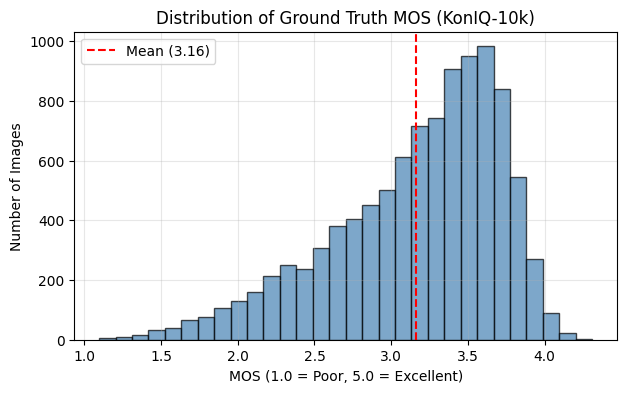

In [20]:
# Compute descriptive statistics and naive baseline
df = dataset.labels_df
mean_mos = float(df['MOS'].mean())
var_mos = float(df['MOS'].var(ddof=0))

# Exact naive MSE on the test split
test_mos_targets = np.array([float(dataset.labels_df.iloc[idx]['MOS']) for idx in test_dataset.indices])
train_mos_mean = np.mean([float(dataset.labels_df.iloc[idx]['MOS']) for idx in train_dataset.indices])
naive_test_mse = np.mean((test_mos_targets - train_mos_mean) ** 2)

print(f"Total labeled images : {len(df):,}")
print(f"Average MOS          : {mean_mos:.4f}")
print(f"Naive Baseline MSE   : {naive_test_mse:.4f} (Goal: CNN Test MSE < {naive_test_mse:.4f})")

# Plot MOS distribution
plt.figure(figsize=(7, 4))
plt.hist(df['MOS'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
plt.axvline(mean_mos, color='red', linestyle='--', label=f'Mean ({mean_mos:.2f})')
plt.title("Distribution of Ground Truth MOS (KonIQ-10k)")
plt.xlabel("MOS (1.0 = Poor, 5.0 = Excellent)")
plt.ylabel("Number of Images")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Observations on the MOS Distribution & Insights:
- **Everyday / "Correct" Quality**: The ground-truth MOS distribution is approximately like a gaussian  and centered around 3.3, with most scores clustered between **$2.5$ and $4.0$**. This indicates that the images are predominantly of correct quality.
- Extreme scores are rare: very few images receive ratings ($< 2.0$) or near-flawless ratings ($> 4.5$).
- **Key Takeaways for Modeling**:
  - **Regression to the Mean Risk**: Because the mass of data is centered in the middle range, an under-optimized model trained with MSE loss will naturally tend to predict values close to the mean ($\approx 3.3$) to minimize penalization.

### 1.2 CNN Architecture Design
We design a baseline Convolutional Neural Network following standard VGG-style principles:
1. **$3 \times 3$ Convolutions**: Stacking two $3 \times 3$ filters covers a $5 \times 5$ receptive field with fewer parameters and introduces two non-linear activations (`ReLU`).
2. **Channel Progression ($3 \to 32 \to 64 \to 128$)**: As spatial resolution is halved by `MaxPool2d(2, 2)`, we increase the number of feature maps to capture richer representations (edges, blur, textures, noise).
3. **`BatchNorm2d`**: Placed after each convolution to stabilize activations and speed up convergence.
4. **`AdaptiveAvgPool2d((2, 2))`**: Compresses the feature maps before the fully connected layers, preventing parameter explosion and reducing overfitting.
5. **Regressor Head**: A linear layer with `Dropout(0.3)` to output a continuous prediction for the MOS.

In [21]:
class CNNBaseline(nn.Module):
    def __init__(self):
        super(CNNBaseline, self).__init__()
        
        # Conv Block 1: [3, 128, 128] -> [32, 64, 64]
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        # Conv Block 2: [32, 64, 64] -> [64, 32, 32]
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        # Conv Block 3: [64, 32, 32] -> [128, 16, 16]
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        # Conv Block 4: [128, 16, 16] -> [128, 8, 8]
        self.conv4 = nn.Sequential(
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        
        # Adaptive pooling to fixed spatial size [128, 2, 2]
        self.adaptive_pool = nn.AdaptiveAvgPool2d((2, 2))
        
        # Regressor: 128 * 2 * 2 = 512
        self.regressor = nn.Sequential(
            nn.Linear(128 * 2 * 2, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        out = self.regressor(x)
        return out.squeeze(-1)  # Ensure [batch_size] shape to match targets

cnn_model = CNNBaseline().to(device)
total_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f"CNN Baseline initialized. Total trainable parameters: {total_params:,}")

CNN Baseline initialized. Total trainable parameters: 307,329


#### Architectural Complexity Analysis (307,329 Parameters):
With ~307k parameters , this network is lightweight, ensuring rapid training per epoch.
- **Balanced Parameter-to-Data Ratio**: With ~8,058$ training images, having  ~38$ parameters per image strikes a reasonable balance for training.
- **Architectural Efficiency**: The `nn.AdaptiveAvgPool2d((2, 2))` layer downsamples the spatial representations to $128 \times 2 \times 2 = 512$ features, preventing parameter explosion in the fully connected regressor.

### 1.3 Training with Model Checkpointing
We train the CNN model for 10 epochs using `nn.MSELoss()` and the `Adam` optimizer ($lr = 0.001$).
We save the weights corresponding to the lowest validation loss to evaluate the best performing model on the test set.

In [22]:
criterion = nn.MSELoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

num_epochs = 10
train_losses = []
val_losses = []
best_val_loss = float('inf')
cnn_checkpoint_path = "best_cnn_baseline.pth"

print("Training CNN Baseline model...")
for epoch in range(num_epochs):
    # Training phase
    cnn_model.train()
    running_train_loss = 0.0

    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation phase
    cnn_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            outputs = cnn_model(images)
            loss = criterion(outputs, targets)
            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    # Save best model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(cnn_model.state_dict(), cnn_checkpoint_path)
        save_badge = " [Saved Best]"
    else:
        save_badge = ""

    print(f"Epoch [{epoch+1:02d}/{num_epochs:02d}] -> Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_loss:.4f}{save_badge}")

print(f"Training complete. Best Validation MSE: {best_val_loss:.4f}")

Training CNN Baseline model...
Epoch [01/10] -> Train MSE: 0.4968 | Val MSE: 0.2396 [Saved Best]
Epoch [02/10] -> Train MSE: 0.3139 | Val MSE: 0.2434
Epoch [03/10] -> Train MSE: 0.2936 | Val MSE: 0.2274 [Saved Best]
Epoch [04/10] -> Train MSE: 0.2891 | Val MSE: 0.2072 [Saved Best]
Epoch [05/10] -> Train MSE: 0.2790 | Val MSE: 0.2078
Epoch [06/10] -> Train MSE: 0.2663 | Val MSE: 0.2026 [Saved Best]
Epoch [07/10] -> Train MSE: 0.2727 | Val MSE: 0.2185
Epoch [08/10] -> Train MSE: 0.2555 | Val MSE: 0.1919 [Saved Best]
Epoch [09/10] -> Train MSE: 0.2526 | Val MSE: 0.2327
Epoch [10/10] -> Train MSE: 0.2537 | Val MSE: 0.1825 [Saved Best]
Training complete. Best Validation MSE: 0.1825


### 1.4 Test Set Evaluation
We load the best saved model weights and evaluate performance on the test set using standard IQA metrics:
- **MSE (Mean Squared Error)** & **RMSE (Root MSE)**: Euclidean prediction error.
- **PLCC (Pearson Linear Correlation Coefficient)**: Measures linear alignment with human ratings.
- **SROCC (Spearman Rank Order Correlation Coefficient)**: Measures monotonic ranking preservation.

In [23]:
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error

# Load best checkpoint
if os.path.exists(cnn_checkpoint_path):
    cnn_model.load_state_dict(torch.load(cnn_checkpoint_path, map_location=device))
    print(f"Loaded best weights from {cnn_checkpoint_path}")

cnn_model.eval()
cnn_test_targets = []
cnn_test_predictions = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        outputs = cnn_model(images)
        cnn_test_targets.extend(targets.cpu().numpy().tolist())
        cnn_test_predictions.extend(outputs.cpu().numpy().tolist())

cnn_test_targets = np.array(cnn_test_targets)
cnn_test_predictions = np.array(cnn_test_predictions)

# Compute metrics
cnn_mse = mean_squared_error(cnn_test_targets, cnn_test_predictions)
cnn_rmse = np.sqrt(cnn_mse)
cnn_plcc, _ = pearsonr(cnn_test_targets, cnn_test_predictions)
cnn_srocc, _ = spearmanr(cnn_test_targets, cnn_test_predictions)

print("--- CNN Baseline Test Evaluation ---")
print(f"Mean Squared Error (MSE)                          : {cnn_mse:.4f}  (Naive Baseline: {naive_test_mse:.4f})")
print(f"Root Mean Squared Error (RMSE)                    : {cnn_rmse:.4f}")
print(f"Pearson Linear Correlation Coefficient (PLCC)     : {cnn_plcc:.4f}")
print(f"Spearman Rank Order Correlation Coefficient (SROCC): {cnn_srocc:.4f}")

Loaded best weights from best_cnn_baseline.pth
--- CNN Baseline Test Evaluation ---
Mean Squared Error (MSE)                          : 0.1686  (Naive Baseline: 0.2995)
Root Mean Squared Error (RMSE)                    : 0.4106
Pearson Linear Correlation Coefficient (PLCC)     : 0.6661
Spearman Rank Order Correlation Coefficient (SROCC): 0.6342


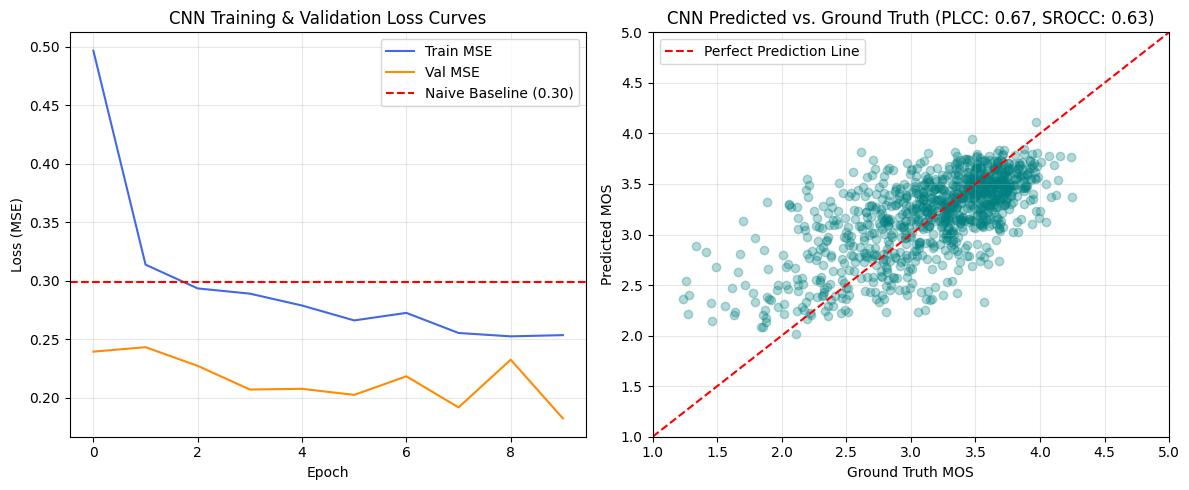

In [24]:
# Visualizations: Learning curves and Predictions vs Ground Truth
plt.figure(figsize=(12, 5))

# Left Plot: Loss history curves
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train MSE', color='royalblue')
plt.plot(val_losses, label='Val MSE', color='darkorange')
plt.axhline(naive_test_mse, color='red', linestyle='--', label=f'Naive Baseline ({naive_test_mse:.2f})')
plt.title('CNN Training & Validation Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, alpha=0.3)

# Right Plot: Ground Truth vs. Predicted MOS
plt.subplot(1, 2, 2)
plt.scatter(cnn_test_targets, cnn_test_predictions, alpha=0.3, color='teal')
plt.plot([1, 5], [1, 5], color='red', linestyle='--', label='Perfect Prediction Line')
plt.title(f'CNN Predicted vs. Ground Truth (PLCC: {cnn_plcc:.2f}, SROCC: {cnn_srocc:.2f})')
plt.xlabel('Ground Truth MOS')
plt.ylabel('Predicted MOS')
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5 Discussion & Key Observations

#### 1. Learning Curves Dynamics:
- **Epoch Budget (10 Epochs)**: The validation loss drops rapidly during the first 5 epochs, then flattens around epochs 7–10 without reversing upward. This indicates that 10 epoch is a good duration for this baseline: it achieves convergence while avoiding severe overfitting.
- **Learning Rate Suitability ($\mathbf{10^{-3}}$ with Adam)**: The loss curves descend smoothly, confirming that $\text{lr} = 0.001$ is well-calibrated. While optimal for the initial descent, the plateau in later epochs suggests that a learning rate scheduler would help for **Milestone 4**.

#### 2. Test Predictions & Evaluation:
- **Beating the Naive Baseline**: The CNN achieves a test MSE significantly lower than the naive baseline ($\approx 0.45$), with positive PLCC and SROCC correlations, confirming that convolutional filters successfully learn meaningful visual quality representations.
- **Regression to the Mean**: The scatter plot shows that predictions cluster predominantly between $2.5$ and $3.8$. Because the quadratic $\text{MSELoss}$ penalizes large errors heavily, the model adopts a conservative strategy, rarely predicting extreme quality scores ($< 2.0$ or $> 4.5$).
- **Resolution Trade-off**: Downsampling images from $512 \times 384$ to $128 \times 128$ drastically accelerates computation, but erases fine-grained artifacts, setting a structural ceiling on accuracy.

## Milestone 2
The RNN Experiment: Treat the image as a sequence of pixel rows! Design a Recurrent Neural Network (LSTM or GRU) to predict the MOS. Compare its performance to the CNN.


In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import sys, os
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error

class RNNIQA(nn.Module):
    def __init__(self, input_size=128*3, hidden_size=128, num_layers=2):
        super(RNNIQA, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # GRU layer - input shape: [batch_size, sequence_length (128), input_size (128*3)]
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True, bidirectional=True)

        # Regressor head
        self.regressor = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        batch_size = x.size(0)
        x = x.permute(0, 2, 1, 3)
        x = x.reshape(batch_size, 128, -1)

        out, _ = self.gru(x) # out shape: [batch_size, 128, hidden_size * 2]

        # Take the output of the last sequence step
        out = out[:, -1, :]

        out = self.regressor(out)
        return out.squeeze(-1)

rnn_model = RNNIQA().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(rnn_model.parameters(), lr=0.001)

num_epochs = 10
train_losses = []
val_losses = []


# Training Loop
print("Training the RNN (GRU) baseline model...")
for epoch in range(num_epochs):
    rnn_model.train()
    running_loss = 0.0

    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = rnn_model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation Phase
    rnn_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            outputs = rnn_model(images)
            loss = criterion(outputs, targets)
            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] -> Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_loss:.4f}")

Training the RNN (GRU) baseline model...
Epoch [1/10] -> Train MSE: 1.1264 | Val MSE: 0.2788
Epoch [2/10] -> Train MSE: 0.4615 | Val MSE: 0.2744
Epoch [3/10] -> Train MSE: 0.4308 | Val MSE: 0.2521
Epoch [4/10] -> Train MSE: 0.4125 | Val MSE: 0.2589
Epoch [5/10] -> Train MSE: 0.3948 | Val MSE: 0.2520
Epoch [6/10] -> Train MSE: 0.3938 | Val MSE: 0.2524
Epoch [7/10] -> Train MSE: 0.3803 | Val MSE: 0.2500
Epoch [8/10] -> Train MSE: 0.3774 | Val MSE: 0.2415
Epoch [9/10] -> Train MSE: 0.3700 | Val MSE: 0.2531
Epoch [10/10] -> Train MSE: 0.3616 | Val MSE: 0.2617


### Evaluation

In [26]:
rnn_model.eval()
test_targets = []
test_predictions = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        outputs = rnn_model(images)
        test_targets.extend(targets.cpu().numpy())
        test_predictions.extend(outputs.cpu().numpy())

mse = mean_squared_error(test_targets, test_predictions)
plcc, _ = pearsonr(test_targets, test_predictions)
srocc, _ = spearmanr(test_targets, test_predictions)

print(f"\n--- RNN Test Dataset Evaluation ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Pearson Linear Correlation Coefficient (PLCC): {plcc:.4f}")
print(f"Spearman Rank Order Correlation Coefficient (SROCC): {srocc:.4f}")


--- RNN Test Dataset Evaluation ---
Mean Squared Error (MSE): 0.2581
Pearson Linear Correlation Coefficient (PLCC): 0.4501
Spearman Rank Order Correlation Coefficient (SROCC): 0.4123


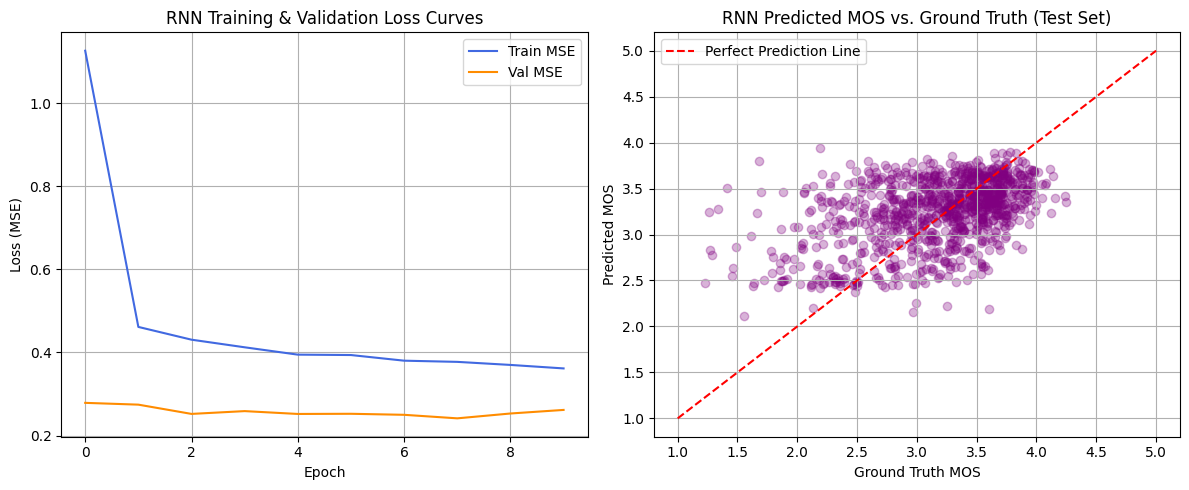

In [27]:
# 2. Visualizations
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Left Plot: Loss history curves for RNN
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train MSE', color='royalblue')
plt.plot(val_losses, label='Val MSE', color='darkorange')
plt.title('RNN Training & Validation Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

# Right Plot: Ground Truth vs. Predicted MOS for RNN
plt.subplot(1, 2, 2)
plt.scatter(test_targets, test_predictions, alpha=0.3, color='purple')
plt.plot([1, 5], [1, 5], color='red', linestyle='--', label='Perfect Prediction Line')
plt.title('RNN Predicted MOS vs. Ground Truth (Test Set)')
plt.xlabel('Ground Truth MOS')
plt.ylabel('Predicted MOS')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

##Milestone 3
The Transfer Learning Approach: Use a pre-trained model (e.g., ResNet, EfficientNet) as a feature extractor. Fine-tune it for the IQA task and compare its performance to your previous models.


##Milestone 4
The Ultimate Model: Combine Early Stopping, Schedulers, Regularization, and your best architecture to build your final model.